# Cislunar Highways: the pipeline in one notebook

Every step uses the hand-written `cislunar` package. Run top to bottom (about 2 minutes).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cislunar import cr3bp, lagrange, orbits, manifolds, shooting, transfer
from cislunar.constants import EARTH_MOON as U, R_EARTH_KM, R_MOON_KM
MU, L, D = U.mu, U.length_km, U.time_days
print(f'mu = {MU:.10f}, time unit = {D:.3f} days, velocity unit = {U.velocity_km_s:.4f} km/s')

mu = 0.0121505839, time unit = 4.342 days, velocity unit = 1.0245 km/s


## 1. Lagrange points and the Jacobi constant
At an equilibrium the velocity is zero, so `C = 2Ω`.

In [2]:
pts, C = lagrange.lagrange_points(MU), lagrange.jacobi_at_points(MU)
for k in pts: print(k, np.round(pts[k], 8), f'C = {C[k]:.6f}')

L1 [0.83691513 0.         0.        ] C = 3.200344
L2 [1.15568216 0.         0.        ] C = 3.184163
L3 [-1.00506265  0.          0.        ] C = 3.024150
L4 [0.48784942 0.8660254  0.        ] C = 3.000000
L5 [ 0.48784942 -0.8660254   0.        ] C = 3.000000


## 2. Linear stability at L1: saddle × center × center

In [3]:
m = lagrange.collinear_modes(1, MU)
print(f'lambda = {m.lam:.4f} (errors grow by e every {D / m.lam:.2f} days), omega_p = {m.omega_p:.4f}, nu = {m.nu:.4f}')

lambda = 2.9321 (errors grow by e every 1.48 days), omega_p = 2.3344, nu = 2.2688


## 3. From a planar Lyapunov orbit to a halo orbit
Find where the vertical stability index crosses +1, step off in z, then follow the family with pseudo-arclength continuation.

In [4]:
bif = orbits.find_halo_bifurcation(2, MU, 0.020, 0.030)
fam = orbits.pseudo_arclength_family(orbits.halo_from_bifurcation(bif, 2e-3), 14, 0.008, MU, direction=np.array([0, 1, 0]))
halo = fam.orbits[-1]
st = orbits.stability(halo)
print(f'{len(fam.orbits)} halos; last: z0 = {halo.X0[2] * L:,.0f} km, period {halo.period * D:.2f} d, closure {orbits.closure_error(halo):.1e}, lambda_u = {st.lambda_unstable:.0f}')

14 halos; last: z0 = 61,960 km, period 13.55 d, closure 4.0e-14, lambda_u = 138


## 4. The stable and unstable manifolds ("highways")

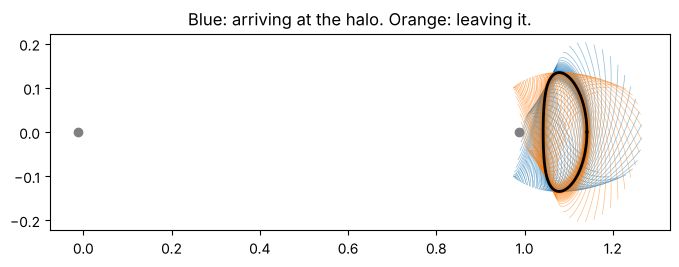

In [5]:
s = manifolds.sample_orbit(halo, 30)
fig, ax = plt.subplots(figsize=(8, 5))
for kind, col in (('s', 'tab:blue'), ('u', 'tab:orange')):
    for sign in (1.0, -1.0):
        for trj in manifolds.generate_tube(halo, kind, sign, 6.0, r_earth=R_EARTH_KM / L, r_moon=R_MOON_KM / L, samples=s):
            ax.plot(trj.X[:, 0], trj.X[:, 1], color=col, lw=0.5, alpha=0.5)
H = shooting.full_period(halo, n_points=300).X
ax.plot(H[:, 0], H[:, 1], 'k', lw=2); ax.plot([-MU, 1 - MU], [0, 0], 'o', color='gray')
ax.set_aspect('equal'); ax.set_title('Blue: arriving at the halo. Orange: leaving it.'); plt.show()

## 5. Direct vs low-energy transfer (reduced search)
The full study (`scripts/run_phase11_transfer.py`) corrects more candidates and refines them; see `docs/results.md`.

In [6]:
cands = transfer.design_candidates(halo, U, n_correct=8, n_direct=4, n_strands=30)
for kind in ('direct', 'manifold'):
    b = min((c for c in cands if c['kind'] == kind), key=lambda c: c['total'])
    print(f"{kind:9}: TLI {b['dv1'] * 1000:,.0f} m/s + second burn {b['dv2'] * 1000:,.0f} m/s = {b['total'] * 1000:,.0f} m/s, {b['tof_days']:.1f} days")

direct   : TLI 3,181 m/s + second burn 843 m/s = 4,024 m/s, 5.7 days
manifold : TLI 3,113 m/s + second burn 451 m/s = 3,564 m/s, 128.1 days
